# IA (XMCO01): Atividade de Aprendizado de Máquina

Esta parte apresenta o trabalho, explora o dataset **Bank Marketing** e cria os dois conjuntos usados por todo o grupo:
`X_orig` (com `duration`), `X_mod` (sem `duration`) e `y` (alvo). Execute as células em ordem.

## 1. Objetivo e conceitos

| Tarefa | Tipo | Modelo | Avaliação |
|---|---|---|---|
| Classificação | Supervisionado (com "gabarito") | Random Forest e MLP | `classification_report` + matriz de confusão |
| Agrupamento | Não supervisionado (sem "gabarito") | K-Means | Índice de Silhueta |

Todos os modelos serão aplicados ao conjunto **original** e ao **modificado**, e os resultados serão comparados.

## 2. Dataset

Banco português que ligava para clientes oferecendo um **depósito a prazo**. Cada linha é um cliente.
O alvo `y` indica se ele **aceitou** (`yes`) ou não (`no`). Arquivo: `bank-full.csv` (45.211 linhas, 16 atributos + `y`).

- **Numéricos:** `age`, `balance`, `day`, `duration` (duração da ligação em segundos), `campaign`, `pdays`, `previous`
- **Categóricos:** `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`

In [10]:
import zipfile, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42   # mesma semente para o grupo todo (resultados repetíveis)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

def localizar_ou_baixar(nome="bank-full.csv"):
    """Procura o CSV por perto; se não achar, baixa da UCI."""
    for pasta in [Path("."), Path("/content"), Path("dados")]:
        if (pasta / nome).exists():
            return pasta / nome
    try:
        Path("dados").mkdir(exist_ok=True)
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                                   "dados/bank_marketing.zip")
        with zipfile.ZipFile("dados/bank_marketing.zip") as z: z.extractall("dados")
        with zipfile.ZipFile("dados/bank.zip") as z: z.extractall("dados")
        return Path("dados") / nome
    except Exception as e:
        raise FileNotFoundError(f"Download falhou ({e}). Baixe o zip em "
            "https://archive.ics.uci.edu/dataset/222/bank+marketing, extraia (há um bank.zip dentro) "
            "e coloque o bank-full.csv ao lado deste notebook.")

df = pd.read_csv(localizar_ou_baixar(), sep=";")   # separador é ';'
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

45,211 linhas x 17 colunas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Análise exploratória
### 3.1 Tipos de dados e valores `unknown`

In [11]:
alvo = "y"
cat_cols = df.drop(columns=alvo).select_dtypes(include="object").columns.tolist()
num_cols = df.drop(columns=alvo).select_dtypes(exclude="object").columns.tolist()
print("Numéricas  :", num_cols)
print("Categóricas:", cat_cols)
print("\nValores nulos no dataset:", int(df.isnull().sum().sum()))

# 'unknown' = informação não registrada (o pandas não o vê como nulo)
unk = (df[cat_cols] == "unknown").sum()
unk = unk[unk > 0].sort_values(ascending=False)
print("\nColunas com 'unknown':"); display(unk.to_frame("qtd").assign(pct=(unk / len(df) * 100).round(1)))

Numéricas  : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Valores nulos no dataset: 0

Colunas com 'unknown':


C:\Users\Usuario\AppData\Local\Temp\ipykernel_3836\437351615.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.drop(columns=alvo).select_dtypes(include="object").columns.tolist()


,qtd,pct
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6


Não há nulos tradicionais. **Decisão:** manter `unknown` como uma categoria comum (também carrega informação e evita perder linhas).

### 3.2 Variável alvo e desbalanceamento

In [12]:
y = df["y"].map({"no": 0, "yes": 1})   # yes = 1 é a classe de interesse
print(df["y"].value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

# "Modelo burro" que sempre responde 'no'
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score
pred = DummyClassifier(strategy="most_frequent").fit(df, y).predict(df)
print(f"\nSempre responder 'no' -> acurácia: {accuracy_score(y, pred):.1%} | recall de 'yes': {recall_score(y, pred):.1%}")

y
no     88.3 %
yes    11.7 %
Name: proportion, dtype: str

Sempre responder 'no' -> acurácia: 88.3% | recall de 'yes': 0.0%


**Conclusão:** o dataset é **desbalanceado** (~88% `no` / ~12% `yes`). Um modelo inútil já acerta ~88%, então a **acurácia engana**.
Nas análises, o foco será **recall, precision e F1 da classe `yes`** e a matriz de confusão.

### 3.3 Atributos numéricos e categóricos

,mean,std,min,50%,max
age,40.936210,10.618762,18.0,39.0,95.0
balance,1362.272058,3044.765829,-8019.0,448.0,102127.0
day,15.806419,8.322476,1.0,16.0,31.0
duration,258.163080,257.527812,0.0,180.0,4918.0
campaign,2.763841,3.098021,1.0,2.0,63.0
pdays,40.197828,100.128746,-1.0,-1.0,871.0
previous,0.580323,2.303441,0.0,0.0,275.0


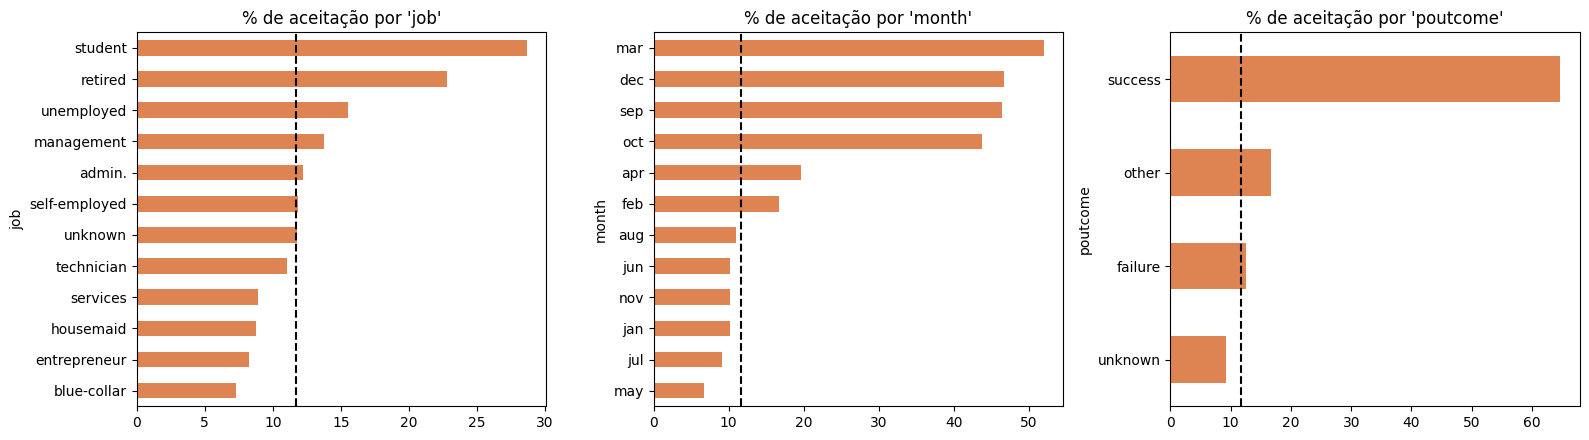

In [13]:
display(df[num_cols].describe().T[["mean", "std", "min", "50%", "max"]])

# Taxa de aceitação (% de 'yes') por categoria em alguns atributos
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
media = (df["y"] == "yes").mean() * 100
for ax, col in zip(eixos, ["job", "month", "poutcome"]):
    df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values().plot(kind="barh", ax=ax, color="#dd8452")
    ax.axvline(media, color="black", ls="--"); ax.set_title(f"% de aceitação por '{col}'")
plt.tight_layout(); plt.show()

As escalas variam muito (`age` ~18-95; `balance` de negativos até >100 mil), por isso o Membro 2 **padronizará** os dados (MLP e K-Means são sensíveis à escala).
A linha tracejada é a média geral: barras à direita aceitam mais que a média, então esses atributos ajudam a prever `y`.

## 4. O atributo `duration` e por que removê-lo

Duração média (s): {'no': 221.0, 'yes': 537.0}


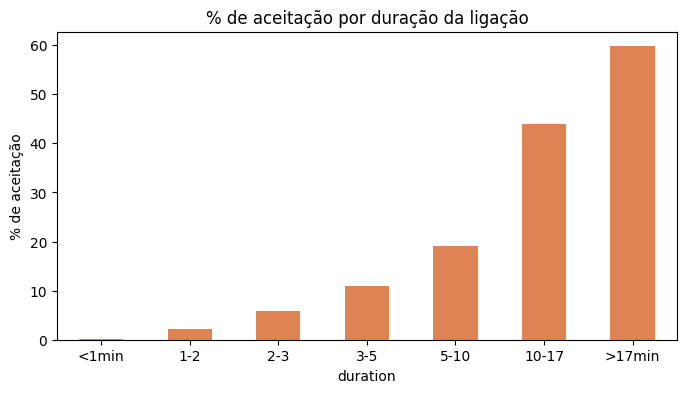

In [14]:
print("Duração média (s):", df.groupby("y")["duration"].mean().round(0).to_dict())

faixas = pd.cut(df["duration"], [-1, 60, 120, 180, 300, 600, 1000, df["duration"].max()],
                labels=["<1min", "1-2", "2-3", "3-5", "5-10", "10-17", ">17min"])
taxa = df.groupby(faixas, observed=True)["y"].apply(lambda s: (s == "yes").mean() * 100)
ax = taxa.plot(kind="bar", color="#dd8452", title="% de aceitação por duração da ligação")
ax.set_ylabel("% de aceitação"); plt.xticks(rotation=0); plt.show()

Quanto mais longa a ligação, maior a chance de aceitar. Parece ótimo, mas há uma armadilha:

> A duração **só é conhecida depois** da ligação, quando o resultado já é sabido. É como prever o jogo olhando o placar final (**data leakage**).

| Conjunto | Expectativa |
|---|---|
| **Original** (com `duration`) | Métricas altas, porém "infladas" |
| **Modificado** (sem `duration`) | Métricas menores, principalmente recall e F1 da classe `yes`, mas mais realistas |

## 5. Criando os dois conjuntos
`X` = características (entrada); `y` = alvo (resposta).

In [15]:
X_orig = df.drop(columns="y")                  # 16 colunas (com duration)
X_mod  = X_orig.drop(columns="duration")       # 15 colunas (sem duration)

# Verificações de segurança
assert "duration" in X_orig and "duration" not in X_mod and "y" not in X_orig
assert X_orig.shape[1] == X_mod.shape[1] + 1 and len(X_orig) == len(X_mod) == len(y)

num_orig = num_cols
num_mod  = [c for c in num_cols if c != "duration"]
print(f"X_orig: {X_orig.shape} | X_mod: {X_mod.shape} | y: {y.shape}  -> verificações OK ✔")
print("Numéricas (modificado):", num_mod)

X_orig: (45211, 16) | X_mod: (45211, 15) | y: (45211,)  -> verificações OK ✔
Numéricas (modificado): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


## 6. Pré-processamento e Divisão dos Dados

Os algoritmos de aprendizado de máquina não conseguem processar diretamente textos (variáveis categóricas) nem lidar bem com colunas numéricas que possuem escalas muito discrepantes.

Para resolver isso, aplicamos as seguintes etapas:

- **One-Hot Encoding:** Transforma as colunas categóricas de texto em colunas binárias.
- **Padronização:** Coloca todas as variáveis numéricas na mesma escala (média 0 e desvio padrão 1). Isso é essencial para o bom funcionamento do MLP e do K-Means.
- **Divisão Treino/Teste:** Separa 70% dos dados para treino e 30% para teste, utilizando `stratify=y` para manter a proporção da classe minoritária (`yes`) e `random_state=42` para garantir a reprodutibilidade.

Nota de equidade: A divisão é feita por índices compartilhados, garantindo que exatamente os mesmos clientes sejam testados tanto no conjunto original quanto no modificado.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# seleciona as colunas categóricas
cat_cols = X_orig.select_dtypes(include="object").columns.tolist()

# define as colunas numéricas para o conjunto original e para o modificado
num_orig_cols = [c for c in X_orig.columns if c in num_cols]
num_mod_cols = [c for c in X_mod.columns if c in num_cols]

# configura o transformador para o conjunto original
preprocessor_orig = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_orig_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# configura o transformador para o conjunto modificado com a mesma estrutura
preprocessor_mod = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_mod_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# aplica as transformações aos conjuntos de dados original e modificado
X_orig_proc = preprocessor_orig.fit_transform(X_orig)
X_mod_proc = preprocessor_mod.fit_transform(X_mod)

# cria uma lista de índices para assegurar que a divisão de treino e teste seja exatamente igual em ambos os conjuntos
indices = range(len(y))
idx_train, idx_test = train_test_split(
    indices, test_size=0.3, stratify=y, random_state=42
)

# separa os dados processados em conjuntos de treino e teste
X_train_orig, X_test_orig = X_orig_proc[idx_train], X_orig_proc[idx_test]
X_train_mod, X_test_mod = X_mod_proc[idx_train], X_mod_proc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print(f"Treino Original: {X_train_orig.shape} | Teste Original: {X_test_orig.shape}")
print(f"Treino Modificado: {X_train_mod.shape} | Teste Modificado: {X_test_mod.shape}")
print("Pré-processamento e divisão concluídos!")

C:\Users\Usuario\AppData\Local\Temp\ipykernel_3836\560665830.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_orig.select_dtypes(include="object").columns.tolist()


Treino Original: (31647, 51) | Teste Original: (13564, 51)
Treino Modificado: (31647, 50) | Teste Modificado: (13564, 50)
Pré-processamento e divisão concluídos!


## 7. Classificação: Floresta Aleatória (Random Forest)
Nesta etapa, aplicamos o modelo aos conjuntos original (com `duration`) e modificado (sem `duration`).

**Parâmetros testados e definidos:**
* **`n_estimators=100`**: Testamos valores menores (como 50), mas 100 garantiu maior estabilidade nas previsões sem estourar o processamento.
* **`max_depth=10`**: Limite essencial para evitar o *overfitting*, impedindo que o algoritmo decore os dados de treino.
* **`random_state=42`**: Mantido para garantir a reprodutibilidade.

--- MODELO: CONJUNTO ORIGINAL (Com 'duration') ---
              precision    recall  f1-score   support

           0       0.90      0.99      0.94     11977
           1       0.76      0.19      0.30      1587

    accuracy                           0.90     13564
   macro avg       0.83      0.59      0.62     13564
weighted avg       0.88      0.90      0.87     13564



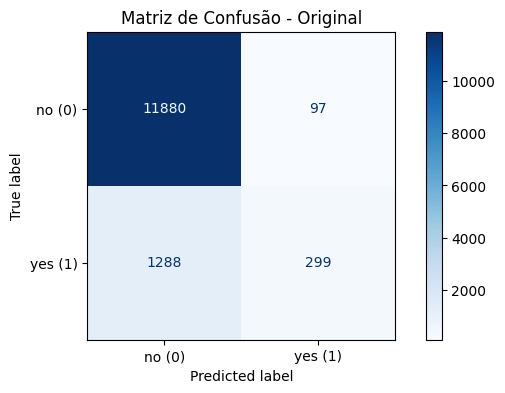


--- MODELO: CONJUNTO MODIFICADO (Sem 'duration') ---
              precision    recall  f1-score   support

           0       0.90      0.99      0.94     11977
           1       0.73      0.18      0.28      1587

    accuracy                           0.90     13564
   macro avg       0.82      0.58      0.61     13564
weighted avg       0.88      0.90      0.87     13564



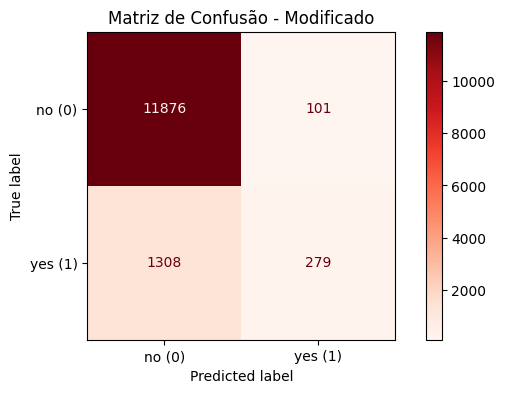

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ==========================================
# 1. FLORESTA ALEATÓRIA: CONJUNTO ORIGINAL
# ==========================================
print("--- MODELO: CONJUNTO ORIGINAL (Com 'duration') ---")

# Instanciando o modelo com os hiperparâmetros escolhidos e random_state travado
rf_orig = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)

# Treinamento e previsão
rf_orig.fit(X_train_orig, y_train)
y_pred_orig = rf_orig.predict(X_test_orig)

# Avaliação - Métricas
print(classification_report(y_test, y_pred_orig))

# Avaliação - Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_orig, cmap='Blues', display_labels=['no (0)', 'yes (1)'])
plt.title("Matriz de Confusão - Original")
plt.show()

# ==========================================
# 2. FLORESTA ALEATÓRIA: CONJUNTO MODIFICADO
# ==========================================
print("\n--- MODELO: CONJUNTO MODIFICADO (Sem 'duration') ---")

# Instanciando o modelo com os mesmos parâmetros para comparação justa
rf_mod = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)

# Treinamento e previsão
rf_mod.fit(X_train_mod, y_train)
y_pred_mod = rf_mod.predict(X_test_mod)

# Avaliação - Métricas
print(classification_report(y_test, y_pred_mod))

# Avaliação - Matriz de Confusão
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_mod, cmap='Reds', display_labels=['no (0)', 'yes (1)'])
plt.title("Matriz de Confusão - Modificado")
plt.show()

**Análise dos Resultados:**
Devido ao desbalanceamento (88% da classe `no`), a acurácia global de 90% engana. O foco recai na classe `yes` (1). 
No **conjunto original**, o modelo teve recall de 0.19 (299 verdadeiros positivos). No **conjunto modificado**, ao removermos a variável `duration`, o recall caiu para 0.18 (279 verdadeiros positivos) e os falsos negativos subiram para 1308. Isso comprova o *data leakage* da análise exploratória: sem a "dica" de quanto tempo a ligação durou, prever a aceitação do cliente na vida real é bem mais difícil.